In [17]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from functools import reduce
from itertools import product
import calendar
from scipy import stats

In [18]:

BASE_DIR = "clean_dataset"

table_date = [
    'sales_pipeline'
]

date_columns = {
    name: ['engage_date', 'close_date']
    for name in table_date}


dfs = {}

for file in os.listdir(BASE_DIR):

    if file.endswith(".csv"):

        path = os.path.join(BASE_DIR, file)
        name = file.replace(".csv", "")

        dates = date_columns.get(name, None)

     
        df = pd.read_csv(
            path,
            parse_dates=dates
        )

        dfs[name] = df



## Analysis Data

### 
**Account Overview**

account :85
sector  : 10 ['technolgy', 'medical', 'retail', 'software', 'entertainment', 'marketing', 'telecommunications', 'finance', 'employment', 'services']
year_established : min (1979) - max(2017)
revenue : min (4.54) - max(11698.03)
employees : min (9) - max(34288)
office_location  : 15 ['United States', 'Kenya', 'Philipines', 'Japan', 'Italy', 'Norway', 'Korea', 'Jordan', 'Brazil', 'Germany', 'Panama', 'Belgium', 'Romania', 'Poland', 'China']
subsidiary_of  : 8 ['Unknown', 'Acme Corporation', 'Massive Dynamic', 'Bubba Gump', 'Inity', 'Sonron', 'Golddex', 'Warephase']


,sector,total_account,%_distribution
0,employment,4,5.0
1,entertainment,6,7.0
2,finance,8,9.0
3,marketing,8,9.0
4,medical,12,14.0
5,retail,17,20.0
6,services,5,6.0
7,software,7,8.0
8,technolgy,12,14.0
9,telecommunications,6,7.0


,office_location,total_account,%_distribution
0,Belgium,1,1.0
1,Brazil,1,1.0
2,China,1,1.0
3,Germany,1,1.0
4,Italy,1,1.0
5,Japan,1,1.0
6,Jordan,1,1.0
7,Kenya,1,1.0
8,Korea,1,1.0
9,Norway,1,1.0


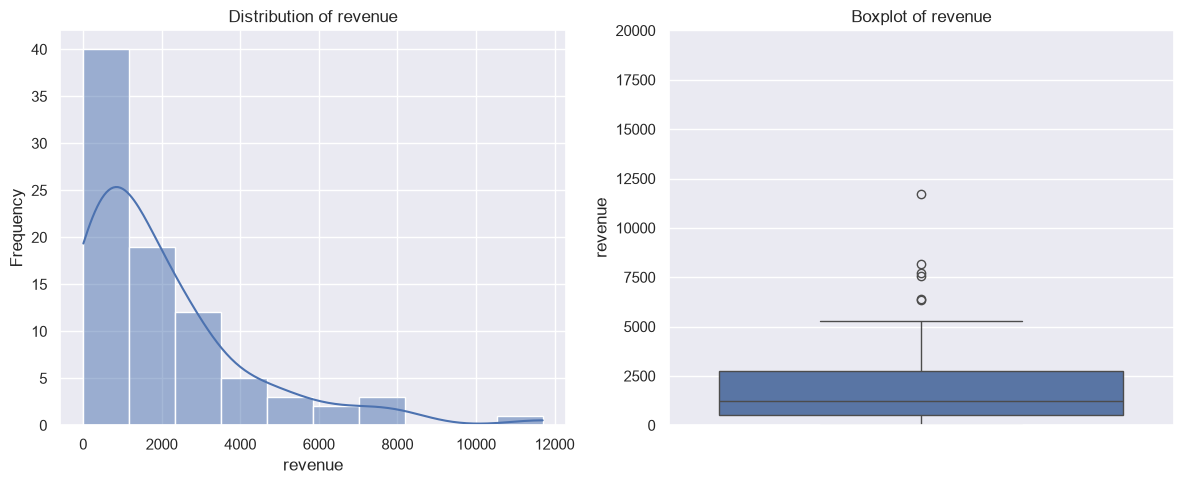

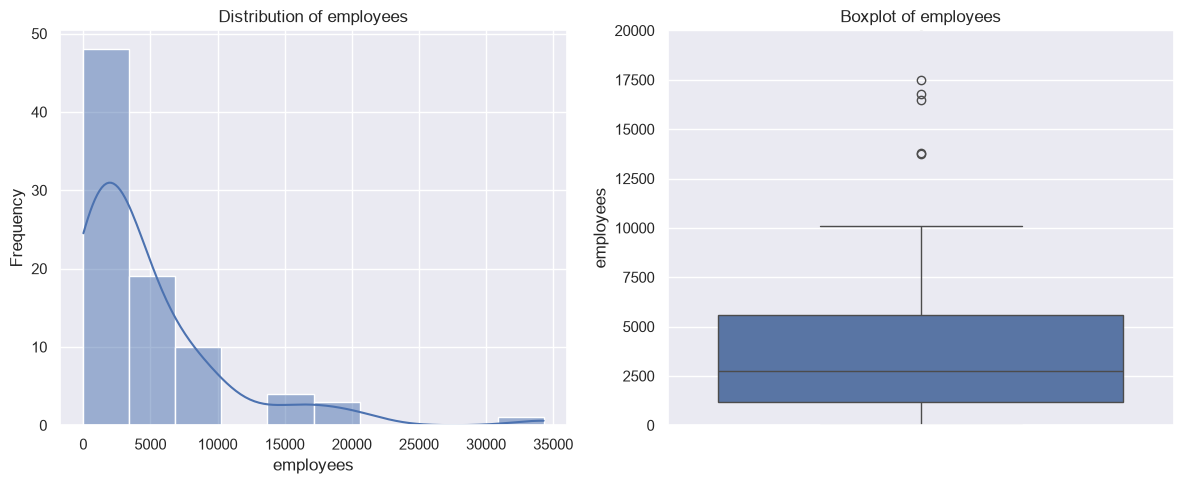

In [19]:
df_accounts = dfs['accounts']

df_products = dfs['products']
df_sales_pipeline = dfs['sales_pipeline']
df_sales_pipeline_Won = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Won']
df_sales_pipeline_Lost = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Lost']


columns = df_accounts.columns

for column in columns :
    if column == "account" :
        print(f'{column} :{df_accounts[column].nunique()}')
    elif column in ['sector', 'office_location', 'subsidiary_of']:
        print(f"{column}  : {df_accounts[column].nunique()} {list(df_accounts[column].unique())}")
    else :
        print(f'{column} : min ({df_accounts[column].min()}) - max({df_accounts[column].max()})')

sector_distribution = (
    df_accounts
    .groupby('sector')
    .agg(total_account = ('account','count'))
    .reset_index()
)
sector_distribution['%_distribution'] = (
    (sector_distribution['total_account']/
    sector_distribution['total_account'].sum())*100
).round(0)

display(sector_distribution)

location_distribution = (
    df_accounts
    .groupby('office_location')
    .agg(total_account = ('account','count'))
    .reset_index()
)
location_distribution['%_distribution'] = (
    (location_distribution['total_account']/
    location_distribution['total_account'].sum())*100
).round(0)

display(location_distribution)


num_columns = ['revenue', 'employees']

for column in num_columns:
    data = df_accounts
    sns.set_style("darkgrid")
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    sns.histplot(
        data=data,
        x=column,
        bins=10,
        kde=True,
        ax=axes[0]
    )
    axes[0].set_title(f'Distribution of {column}')
    axes[0].set_xlabel(f'{column}')
    axes[0].set_ylabel('Frequency')
    plt.ylim(0, 20000) 
    
    sns.boxplot(
        data=data, 
        y=column, 
        ax=axes[1]
    )
    axes[1].set_title(f'Boxplot of {column}')
    axes[1].set_ylabel(f'{column}') 

    plt.tight_layout()
    plt.show()

The company manages a total of **85 accounts** across 10 industry sectors and 15 countries, based on their main office locations. The account portfolio is primarily concentrated in the **Retail, Technology, and Medical sectors** and **US** , indicating a strong presence in these industries.

In terms of company size, approximately **75% of accounts have annual revenue below $2.8M**. Similarly, around **75% have fewer than 5,500 employees**. These figures indicate that the account portfolio is largely composed of companies with relatively smaller revenue and workforce sizes.

Meanwhile, only a small proportion of accounts represent larger enterprises, with annual revenue exceeding $5M or employee counts above 10,000.

Overall, the current account portfolio is predominantly characterized by companies with relatively smaller business scales, while large enterprises represent a smaller segment.

###
**Account Conversion & Acquisition**

In [20]:
print(f"Account-to-Opportunity Conversion Rate : {round((df_sales_pipeline[df_sales_pipeline['account']!='Unidentified']['account'].nunique() / df_accounts['account'].nunique()) * 100, 0)}%")

Acc_Opportunities = (
    df_sales_pipeline[df_sales_pipeline['account']!='Unidentified']
    .groupby('account')
    .agg(total_opportunities = ('opportunity_id','nunique'))
)
print(f"Average Opportunities per Account : {Acc_Opportunities['total_opportunities'].mean().round(0)}")
print(f"Median Opportunities per Account : {Acc_Opportunities['total_opportunities'].median().round(0)}")
print(f"Total Converted Accounts : {df_sales_pipeline_Won['account'].nunique()}")
print(f"Account-to-Customer Conversion Rate : {round((df_sales_pipeline_Won['account'].nunique()/df_sales_pipeline[df_sales_pipeline['account']!='Unidentified']['account'].nunique())*100,0)}%")

Account-to-Opportunity Conversion Rate : 100.0%
Average Opportunities per Account : 100.0
Median Opportunities per Account : 95.0
Total Converted Accounts : 85
Account-to-Customer Conversion Rate : 100.0%


All 85 accounts in the dataset have successfully generated at least one business opportunity, resulting in an Account-to-Opportunity Conversion Rate of 100%.

On average, each account generates 100 opportunities, with a median of 95 opportunities per account. This indicates a substantial volume of opportunities across the account portfolio.

Furthermore, all 85 accounts have recorded at least one Won opportunity, resulting in an Account-to-Customer Conversion Rate of 100%. This means that every account in the dataset has successfully generated at least one customer acquisition.

###
**Monthly Account Performance**

####
*Monthly Account Engagement*

,year-month,account
0,2016-01-01,0
2,2016-02-01,0
4,2016-03-01,0
6,2016-04-01,0
8,2016-05-01,0
10,2016-06-01,0
12,2016-07-01,0
14,2016-08-01,0
16,2016-09-01,0
18,2016-10-01,6


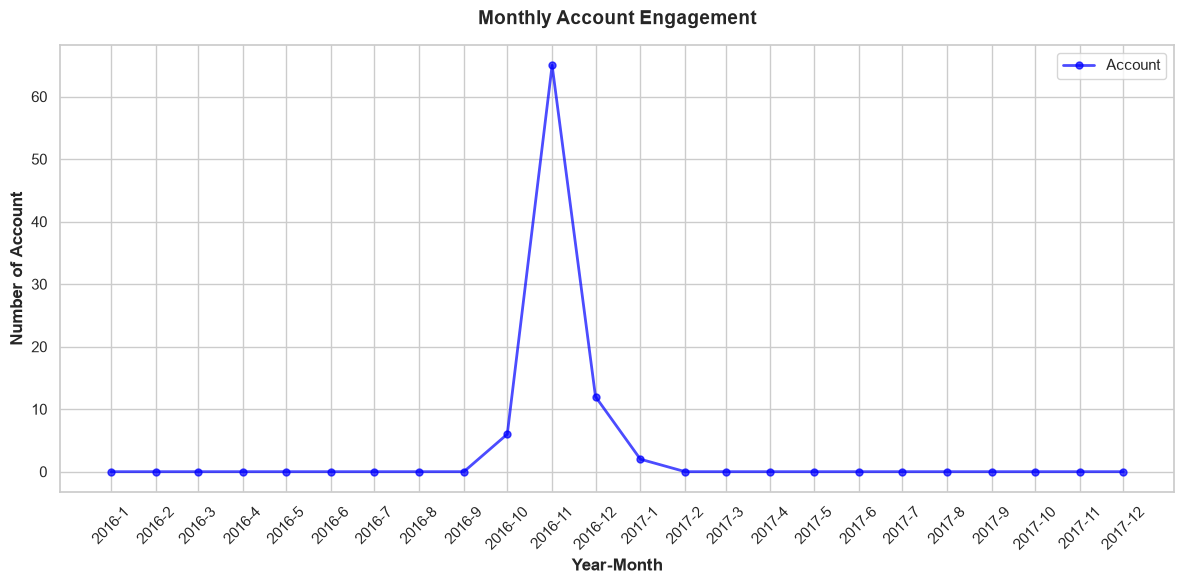

In [21]:
df_sales_pipeline_all_eng = df_sales_pipeline[~df_sales_pipeline['engage_date'].isna()]

data = []
months = np.arange(1, 13)
years = df_sales_pipeline_all_eng['engage_date'].dt.year.dropna().unique()

for month, year in product(months, years):
    start_date = pd.Timestamp(f'{year}-{month}-1')
    last_day = calendar.monthrange(year,month)[1]
    end_date = pd.Timestamp(year,month,last_day)

    hist_acc = df_sales_pipeline_all_eng[(df_sales_pipeline_all_eng['engage_date']<start_date)]['account'].unique()

    monthly_eng_account = df_sales_pipeline_all_eng[
        (df_sales_pipeline_all_eng['engage_date']>=start_date)&
        (df_sales_pipeline_all_eng['engage_date']<=end_date)]['account'].unique()
    
    new_engg_acc = np.setdiff1d(monthly_eng_account,hist_acc)

    data.append(
        {'year' : year,
         'month': month,
         'account': len(new_engg_acc)}
    )

data_eng_acc = pd.DataFrame(data)
data_eng_acc['year-month'] = (
    pd.to_datetime(data_eng_acc['year']
                   .astype(str)+'-'+data_eng_acc['month']
                   .astype(str)
                   ,format = '%Y-%m')
)

data_eng_acc['y-m']= (
    data_eng_acc['year']
    .astype(str)+"-"+data_eng_acc['month']
    .astype(str)
)

monthly_account_engagement = (
    data_eng_acc[['year-month','account']]
    .sort_values('year-month')
)
display(monthly_account_engagement)

data_eng_acc = data_eng_acc.sort_values('year-month')

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

plt.plot(
    data_eng_acc['year-month'],
    data_eng_acc['account'],
    color='blue',
    linestyle='-',
    linewidth=2,
    marker='o',
    markersize=5,
    label='Account',
    alpha=0.7
)

plt.xlabel("Year-Month", fontsize=12, fontweight="bold")
plt.ylabel("Number of Account", fontsize=12, fontweight="bold")

plt.title(
    "Monthly Account Engagement",
    fontsize=14,
    fontweight="bold",
    pad=15
)

for x, y in enumerate(data_eng_acc['account']):
    plt.annotate(
        str(y),
        (x, y),
        textcoords='offset points',
        xytext=(0, 8),
        ha='center',
        fontsize=9,
        fontweight='bold'
    )
    
plt.xticks(
    ticks=data_eng_acc['year-month'],
    labels=data_eng_acc['y-m'],
    rotation=45
)
    

plt.legend()
plt.tight_layout()
plt.show()


The data shows that accounts entered the Engaging stage at different points in time, with the first accounts beginning their engagement in Q4 2016. The engagement process continued over the following months, with all accounts having reached the Engaging stage by Q1 2017.

This indicates that the Sales team progressively engaged with the account portfolio over this period, rather than engaging all accounts simultaneously.

####
*Monthly Customer Acquisition Trend*

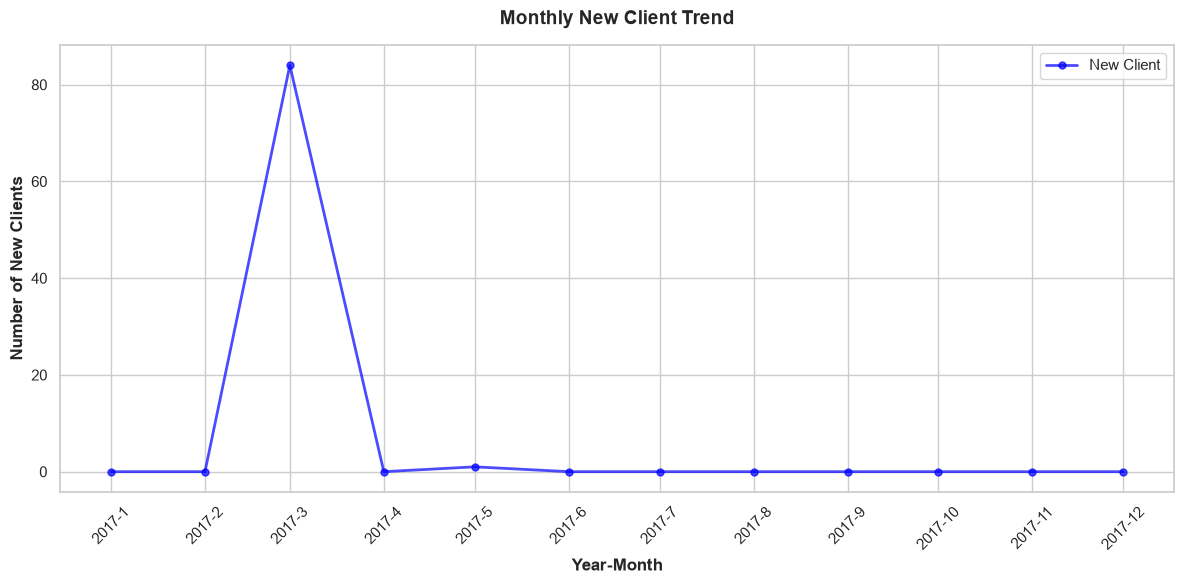

,y-m,new_client,acquitition_rate
0,2017-1,0,0.0
1,2017-2,0,0.0
2,2017-3,84,99.0
3,2017-4,0,0.0
4,2017-5,1,1.0
5,2017-6,0,0.0
6,2017-7,0,0.0
7,2017-8,0,0.0
8,2017-9,0,0.0
9,2017-10,0,0.0


In [22]:
data = []
months = np.arange(1, 13)
years = df_sales_pipeline_Won['close_date'].dt.year.dropna().unique()

for month, year in product(months, years):

    last_day = calendar.monthrange(year, month)[1]
    start_date = pd.Timestamp(f'{year}-{month}-1')
    end_date = pd.Timestamp(year, month, last_day)

    old_client = df_sales_pipeline_Won[df_sales_pipeline_Won['close_date']<start_date]['account'].unique()

    month_client = df_sales_pipeline_Won[
        (df_sales_pipeline_Won['close_date']>=start_date)&
        (df_sales_pipeline_Won['close_date']<=end_date)]['account'].unique()
    
    newest_client = np.setdiff1d(month_client,old_client)
    

    data.append(
        {'year' : year,
         'month': month,
         'new_client' : len(newest_client),
         'accounts': list(newest_client)}
    )

df_monthly_new_client = pd.DataFrame(data)
df_monthly_new_client['year-month'] = (
    pd.to_datetime(
        df_monthly_new_client['year']
        .astype(str)+'-'+df_monthly_new_client['month']
        .astype(str),format = '%Y-%m')
)

df_monthly_new_client['y-m'] = (
    df_monthly_new_client['year']
    .astype(str)+"-"+df_monthly_new_client['month']
    .astype(str)
)

df_monthly_new_client['acquitition_rate'] = (
    round(
        (df_monthly_new_client['new_client']/
         (df_sales_pipeline_Won['account']
          .nunique()
          )
        *100)
        ,)
)

monthly_client_ac = (
    df_monthly_new_client[
        ['y-m',
         'new_client',
         'acquitition_rate']
         ]
)

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

plt.plot(
    df_monthly_new_client['year-month'],
    df_monthly_new_client['new_client'],
    color='blue',
    linestyle='-',
    linewidth=2,
    marker='o',
    markersize=5,
    label='New Client',
    alpha=0.7
)

plt.xlabel("Year-Month", fontsize=12, fontweight="bold")
plt.ylabel("Number of New Clients", fontsize=12, fontweight="bold")

plt.title(
    "Monthly New Client Trend",
    fontsize=14,
    fontweight="bold",
    pad=15
)
    
plt.xticks(
    ticks=df_monthly_new_client['year-month'],
    labels=df_monthly_new_client['y-m'],
    rotation=45
)
plt.legend()
plt.tight_layout()
plt.show()

display(monthly_client_ac)


Customer acquisition was highly concentrated in March 2017, when 84 out of 85 accounts (99%) were converted into customers. The remaining account (1%) achieved its first successful conversion in May 2017.

No additional customers were acquired during the other months. This indicates that customer acquisition did not occur consistently over time but was heavily concentrated in March 2017.

**Account Engagement and Client Acquisition Trend Summary**

Account engagement activity continued to develop from Q4 2016 through April 2017. During this period, the number of engaged opportunities showed a sustained upward trend.

A significant shift occurred in March 2017, when Won Opportunities increased substantially. This coincided with the acquisition of 84 new customers, representing 99% of all converted accounts in the dataset.

These findings suggest a temporal relationship between the ongoing engagement process and the concentration of successful conversions in March 2017. The pattern indicates that customer acquisition was concentrated in a specific period rather than occurring consistently throughout the year.

####
*Time to First Customer Conversion*


In [23]:
first_eng_acc = (
    df_sales_pipeline_all_eng
    .groupby('account')
    .agg(first_engage = ('engage_date','min'))
    .reset_index()
)

first_win_acc = (
    df_sales_pipeline_Won
    .groupby('account')
    .agg(first_win = ('close_date','min'))
    .reset_index()
)

first_date_acc = (
    pd.merge(
        first_eng_acc,
        first_win_acc,
        on ='account',
        how='outer')
)

first_date_acc['day_diff'] = (
    first_date_acc['first_win']-
    first_date_acc['first_engage']
)


print(f"Average Time from First Engagement to First Conversion : {round(((first_date_acc['day_diff'].dt.days).mean()),0)}")
print(f"Shortest Time from First Engagement to First Conversio : {(first_date_acc['day_diff'].dt.days).min()}")
print(f"Longest Time from First Engagement to First Conversion : {(first_date_acc['day_diff'].dt.days).max()}")
display(first_date_acc.sort_values('day_diff',ascending=True))

Average Time from First Engagement to First Conversion : 107.0
Shortest Time from First Engagement to First Conversio : 57
Longest Time from First Engagement to First Conversion : 136


,account,first_engage,first_win,day_diff
49,Newex,2017-01-07,2017-03-05,57 days
66,Streethex,2016-12-26,2017-03-16,80 days
67,Sumace,2016-12-12,2017-03-02,80 days
34,Hottechi,2016-12-10,2017-03-02,82 days
32,Groovestreet,2016-12-19,2017-03-16,87 days
...,...,...,...,...
10,Codehow,2016-10-25,2017-03-01,127 days
37,Isdom,2016-10-25,2017-03-01,127 days
33,Hatfan,2016-10-25,2017-03-02,128 days
8,Cancity,2016-10-20,2017-03-01,132 days


On average, accounts required 107 days (approximately 3.5 months) to become customers after their first engagement. The shortest conversion period was 57 days, while the longest was 136 days.

These findings indicate that converting an engaged account into a customer requires a considerable amount of time, with conversion periods ranging from approximately two to four and a half months.

###
**Account-Level Opportunity Performance**

In [24]:
df_sales_pipeline_closed = (
    df_sales_pipeline[~df_sales_pipeline['close_date']
                      .isna()]
)

df_sales_pipeline_Pros = (
    df_sales_pipeline[df_sales_pipeline['deal_stage']=='Prospecting']
)

df_sales_pipeline_engaging = (
    df_sales_pipeline[df_sales_pipeline['deal_stage']=='Engaging']
)

df_sales_pipeline_Won['diff_days'] = (
    (df_sales_pipeline_Won['close_date']-
     df_sales_pipeline_Won['engage_date'])
     .dt.days
)

df_sales_pipeline_Lost['diff_days'] = (
    df_sales_pipeline_Lost['close_date']-
    df_sales_pipeline_Lost['engage_date']).dt.days


duration_to_lost = (
    df_sales_pipeline_Lost
    .groupby('account')
    .agg(avg_duration_to_lost = ('diff_days','mean'))
    .reset_index()
)

duration_to_lost['avg_duration_to_lost'] = round(duration_to_lost['avg_duration_to_lost'],)

duration_to_win = (
    df_sales_pipeline_Won
    .groupby('account')
    .agg(avg_duration_to_win = ('diff_days','mean'))
    .reset_index()
)

duration_to_win['avg_duration_to_win'] = round(duration_to_win['avg_duration_to_win'],)

df_sales_pipeline_closed['diff_days'] = (
    (df_sales_pipeline_closed['close_date']-
     df_sales_pipeline_closed['engage_date'])
     .dt.days
)

duration_to_close = (
    df_sales_pipeline_closed
    .groupby('account')
    .agg(avg_duration_to_close = ('diff_days','mean'))
    .reset_index()
)

duration_to_close['avg_duration_to_close'] = round(duration_to_close['avg_duration_to_close'],)

df_acc_opp = (
    df_sales_pipeline[df_sales_pipeline['account']!='Unidentified']
    .groupby('account')
    .agg(total_opportunity = ('opportunity_id','count'))
    .reset_index()
)

df_acc_opp_pros = (
    df_sales_pipeline_Pros[df_sales_pipeline_Pros['account']!='Unidentified']
    .groupby('account')
    .agg(prospecting = ('opportunity_id','count'))
    .reset_index()
)

df_acc_opp_eng = (
    df_sales_pipeline_engaging
    .groupby('account')
    .agg(engaging = ('opportunity_id','count'))
    .reset_index()
)

df_acc_opp_won = (
    df_sales_pipeline_Won
    .groupby('account')
    .agg(won= ('opportunity_id','count'), 
         account_value = ('close_value','sum'))
    .reset_index()
)

df_acc_opp_lost = (
    df_sales_pipeline_Lost
    .groupby('account')
    .agg(lost = ('opportunity_id','count'))
    .reset_index()
)

data_accounts = [
    df_acc_opp,
    df_acc_opp_pros,
    df_acc_opp_eng,
    df_acc_opp_won,
    df_acc_opp_lost,
    duration_to_close,
    duration_to_win,
    duration_to_lost,
    first_date_acc
]

df_accounts_summary = reduce(
    lambda df1, df2: pd.merge(
        df1, df2,
        on='account',
        how='outer'
    ),
    data_accounts
)
df_accounts_summary['win_rate'] = (
    round(
        (
            (df_accounts_summary['won']/
             (df_accounts_summary['won']+df_accounts_summary['lost']))
             *100),
             )
)

df_accounts_summary = df_accounts_summary.fillna(0)

print(f" Average Time to Opportunity Closure : {round((df_accounts_summary['avg_duration_to_close'].mean()),0)} days")
print(f" Average Time to Win an Opportunity : {round((df_accounts_summary['avg_duration_to_win'].mean()),0)} days")
print(f" Average Time to Lose an Opportunity : {round((df_accounts_summary['avg_duration_to_lost'].mean()),0)} days")
print(f" Shortest Time to Win an Opportunity : {min(df_accounts_summary['avg_duration_to_win'])} days")
print(f" Longest Time to Win an Opportunity : {max(df_accounts_summary['avg_duration_to_win'])} days")
print(f" Average Opportunity Win Rate : {round((df_accounts_summary['win_rate'].mean()),0)}%")
display(df_accounts_summary.sort_values(['account_value','win_rate','avg_duration_to_win'],ascending=[False,False,True]).head())


 Average Time to Opportunity Closure : 48.0 days
 Average Time to Win an Opportunity : 52.0 days
 Average Time to Lose an Opportunity : 42.0 days
 Shortest Time to Win an Opportunity : 38.0 days
 Longest Time to Win an Opportunity : 74.0 days
 Average Opportunity Win Rate : 63.0%


,account,total_opportunity,prospecting,engaging,won,account_value,lost,avg_duration_to_close,avg_duration_to_win,avg_duration_to_lost,first_engage,first_win,day_diff,win_rate
40,Kan-code,206,1.0,18,115,341455.0,72,47.0,51.0,41.0,2016-11-21,2017-03-04,103 days,61.0
42,Konex,190,3.0,16,108,269245.0,63,44.0,48.0,36.0,2016-11-24,2017-03-13,109 days,63.0
11,Condax,183,3.0,21,105,206410.0,54,49.0,58.0,30.0,2016-11-27,2017-03-03,96 days,66.0
9,Cheers,114,1.0,23,57,198020.0,33,47.0,48.0,45.0,2016-11-01,2017-03-05,124 days,63.0
34,Hottechi,209,2.0,14,111,194957.0,82,48.0,56.0,38.0,2016-12-10,2017-03-02,82 days,58.0


The average time required to close an opportunity was 48 days. However, Won opportunities took an average of 52 days to close, compared to 42 days for Lost opportunities. This suggests that successful opportunities generally required more time to reach a final decision than unsuccessful ones.

The time required to win an opportunity ranged from 38 to 74 days, with an average of 52 days. Meanwhile, the average opportunity win rate reached 63%, indicating a relatively favorable conversion outcome among opportunities that had reached a final decision.

At the account level, Kan-Code demonstrated the strongest overall performance based on the combination of account value, opportunity win rate, and shorter average time to win. In contrast, Golddex recorded the weakest performance across these evaluation criteria.

Furthermore, all 85 accounts eventually generated at least one Won opportunity, although the time required to achieve their first successful conversion varied across accounts.

Overall, the findings indicate positive account conversion outcomes, with all accounts successfully generating customers. However, differences in account value, win rate, and conversion duration highlight variations in commercial performance across accounts. These findings provide opportunities to identify effective account management practices and areas where sales performance could be improved.

###
**Account Characteristics vs. Sales Performance**

In [25]:
data_win_lost_acc = (
    df_accounts_summary[
        ['account',
         'total_opportunity',
         'won',
         'lost',
         'avg_duration_to_close',
         'avg_duration_to_win',
         'avg_duration_to_lost',
         'account_value',
         'win_rate']
         ]
    .copy()
)

df_account_char = pd.merge(df_accounts,data_win_lost_acc, how = 'outer',on='account')
df_account_char['company_age'] = 2018 - df_account_char['year_established']


In [26]:
def breakdown_bar (df,column):
    results = (
        df
        .groupby(column)
        .agg(
            total_opp=('total_opportunity', 'sum')
            ,average_win_rate=('win_rate', 'mean')
            ,total_won=('won', 'sum')
            ,total_lost=('lost', 'sum')
            ,average_duration_to_close=('avg_duration_to_close', 'mean')
            ,average_duration_to_win=('avg_duration_to_win', 'mean')
            ,average_duration_to_lost=('avg_duration_to_lost', 'mean')
            ,total_value_M=('account_value', 'sum')
            ,avg_total_revenue_M = ('account_value','mean'))
        .reset_index()
    )

    columns = results.select_dtypes(include='number').columns
    results[columns] = results[columns].round(0)
    results[['total_value_M', 'avg_total_revenue_M']] = (
    results[['total_value_M', 'avg_total_revenue_M']] / 1e6
).round(2)

    columns = results.select_dtypes(include='number').columns.tolist()
    
    fig, axes = plt.subplots(3, 3, figsize=(30,20))
    axes = axes.flatten()

    for ax, y in zip(axes, columns):

        df_sorted = results.sort_values(
            by=y,
            ascending=False
        )

        bars = ax.bar(
            df_sorted[column],
            df_sorted[y],
            width=0.6,
            color='teal',
            alpha=0.8,
            edgecolor='black',
            linewidth=0.8
        )

        ax.set_title(f'{y} by {column}',fontsize = 20)
        ax.set_xlabel(column,fontsize = 16)
        ax.set_ylabel(y,fontsize = 16)

        ax.bar_label(bars, padding=3, fontsize=15)
        ax.tick_params(
        axis='x',
        rotation=45,
        labelsize=15
        )
        ax.grid(axis='y', linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.show()

In [27]:
def breakdown_plot(df, column):
  results = (
      df.groupby(column)
      .agg(
          total_opp=('total_opportunity', 'sum'),
          average_win_rate=('win_rate', 'mean'),
          total_won=('won', 'sum'),
          total_lost=('lost', 'sum'),
          average_duration_to_close=('avg_duration_to_close', 'mean'),
          average_duration_to_win=('avg_duration_to_win', 'mean'),
          average_duration_to_lost=('avg_duration_to_lost', 'mean'),
          total_value_M=('account_value', 'sum'),
          avg_total_revenue_M=('account_value', 'mean'),
      )
      .reset_index()
  )

  num_cols = results.select_dtypes(include='number').columns
  results[num_cols] = results[num_cols].round(0)
  results[['total_value_M', 'avg_total_revenue_M']] = (
      results[['total_value_M', 'avg_total_revenue_M']] / 1e6
  ).round(2)

  plot_cols = [
      'total_opp',
      'average_win_rate',
      'total_won',
      'total_lost',
      'average_duration_to_close',
      'average_duration_to_win',
      'average_duration_to_lost',
      'total_value_M',
      'avg_total_revenue_M',
  ]

  fig, axes = plt.subplots(3, 3, figsize=(30, 20))
  axes = axes.flatten()
  is_numeric_x = pd.api.types.is_numeric_dtype(results[column])

  for ax, y in zip(axes, plot_cols):
    sub = results[[column, y]].dropna()
    x_vals = sub[column]
    y_vals = sub[y].to_numpy()

    ax.scatter(
        x_vals,
        y_vals,
        s=200,
        color='teal',
        marker='o',
        alpha=0.7,
        edgecolors='black',
        linewidths=0.8,
    )

    if is_numeric_x:
      x_num = x_vals.to_numpy()
      if len(x_num) > 1 and np.std(x_num) > 0 and np.std(y_vals) > 0:
        r_val, _ = stats.pearsonr(x_num, y_vals)
        rho_val, _ = stats.spearmanr(x_num, y_vals)
        corr_text = f'r = {r_val:.2f} | ρ = {rho_val:.2f}'

        slope, intercept = np.polyfit(x_num, y_vals, 1)
        x_line = np.linspace(x_num.min(), x_num.max(), 100)
        y_line = slope * x_line + intercept
        ax.plot(
            x_line,
            y_line,
            color='#D95F02',
            linestyle='--',
            linewidth=3,
            label='Trend',
        )
      else:
        corr_text = 'r = n/a | ρ = n/a'

      ax.text(
          0.03,
          0.96,
          corr_text,
          transform=ax.transAxes,
          fontsize=16,
          fontweight='bold',
          va='top',
          ha='left',
          bbox=dict(
              boxstyle='round,pad=0.4',
              facecolor='white',
              edgecolor='gray',
              alpha=0.9,
          ),
      )

    ax.set_title(f'{y} by {column}', fontsize=20, pad=12)
    ax.set_xlabel(column, fontsize=15)
    ax.set_ylabel(y, fontsize=15)

    ax.tick_params(axis='x', rotation=45, labelsize=15)
    ax.tick_params(axis='y', rotation=45, labelsize=15)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

  plt.tight_layout(pad=2.5, h_pad=3.0, w_pad=2.5)
  # plt.ylim(0,8000)
  plt.show()

####
*Industry & Geographic Profile*

> Sector

> Office Location

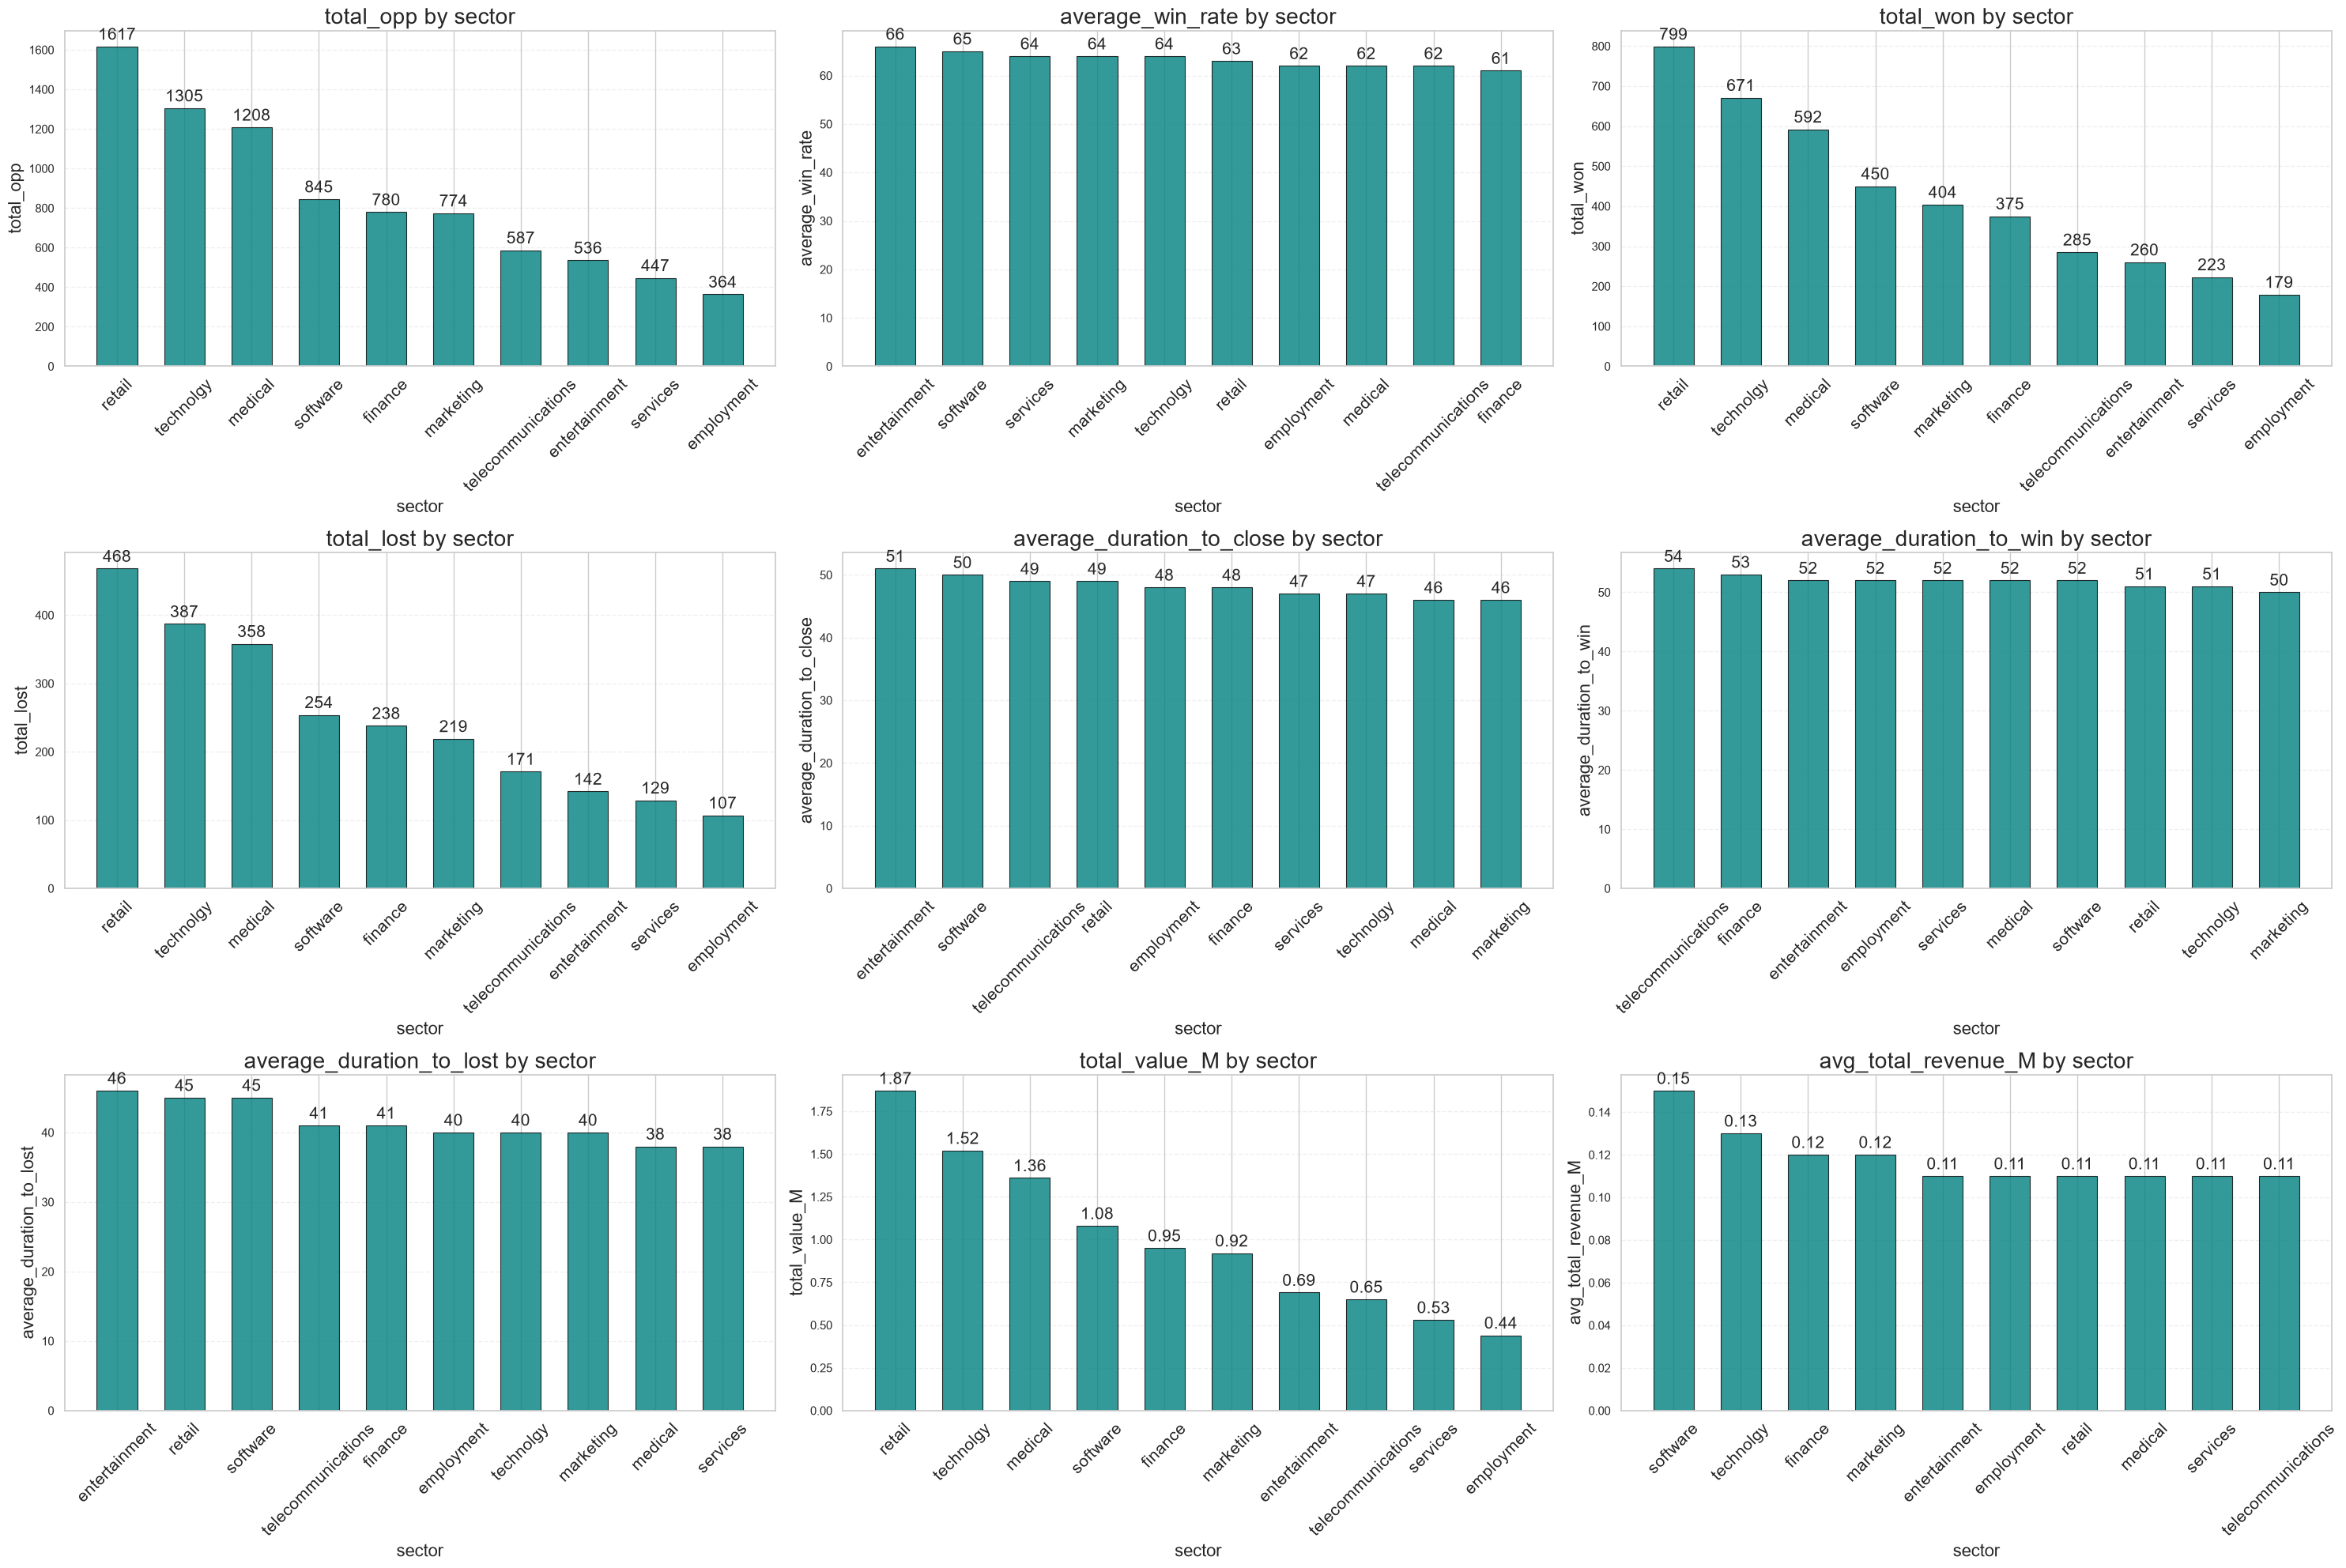

In [28]:
breakdown_bar(df_account_char,'sector')

Retail is the leading sector in terms of sales activity volume and total Won value. Entertainment has the highest average win rate, but also exhibits the longest opportunity closure duration. Software stands out in terms of average Won value per Account and has the second-highest average win rate. Meanwhile, Marketing demonstrates a relatively faster sales cycle compared to other sectors.

If the company aims to increase commercial value, it should prioritize the development of Software and the optimization of Retail. On the other hand, if the goal is to improve sales efficiency, the company should examine the conversion success of Entertainment and the sales processes of Marketing to identify practices that could be adopted across other sectors.

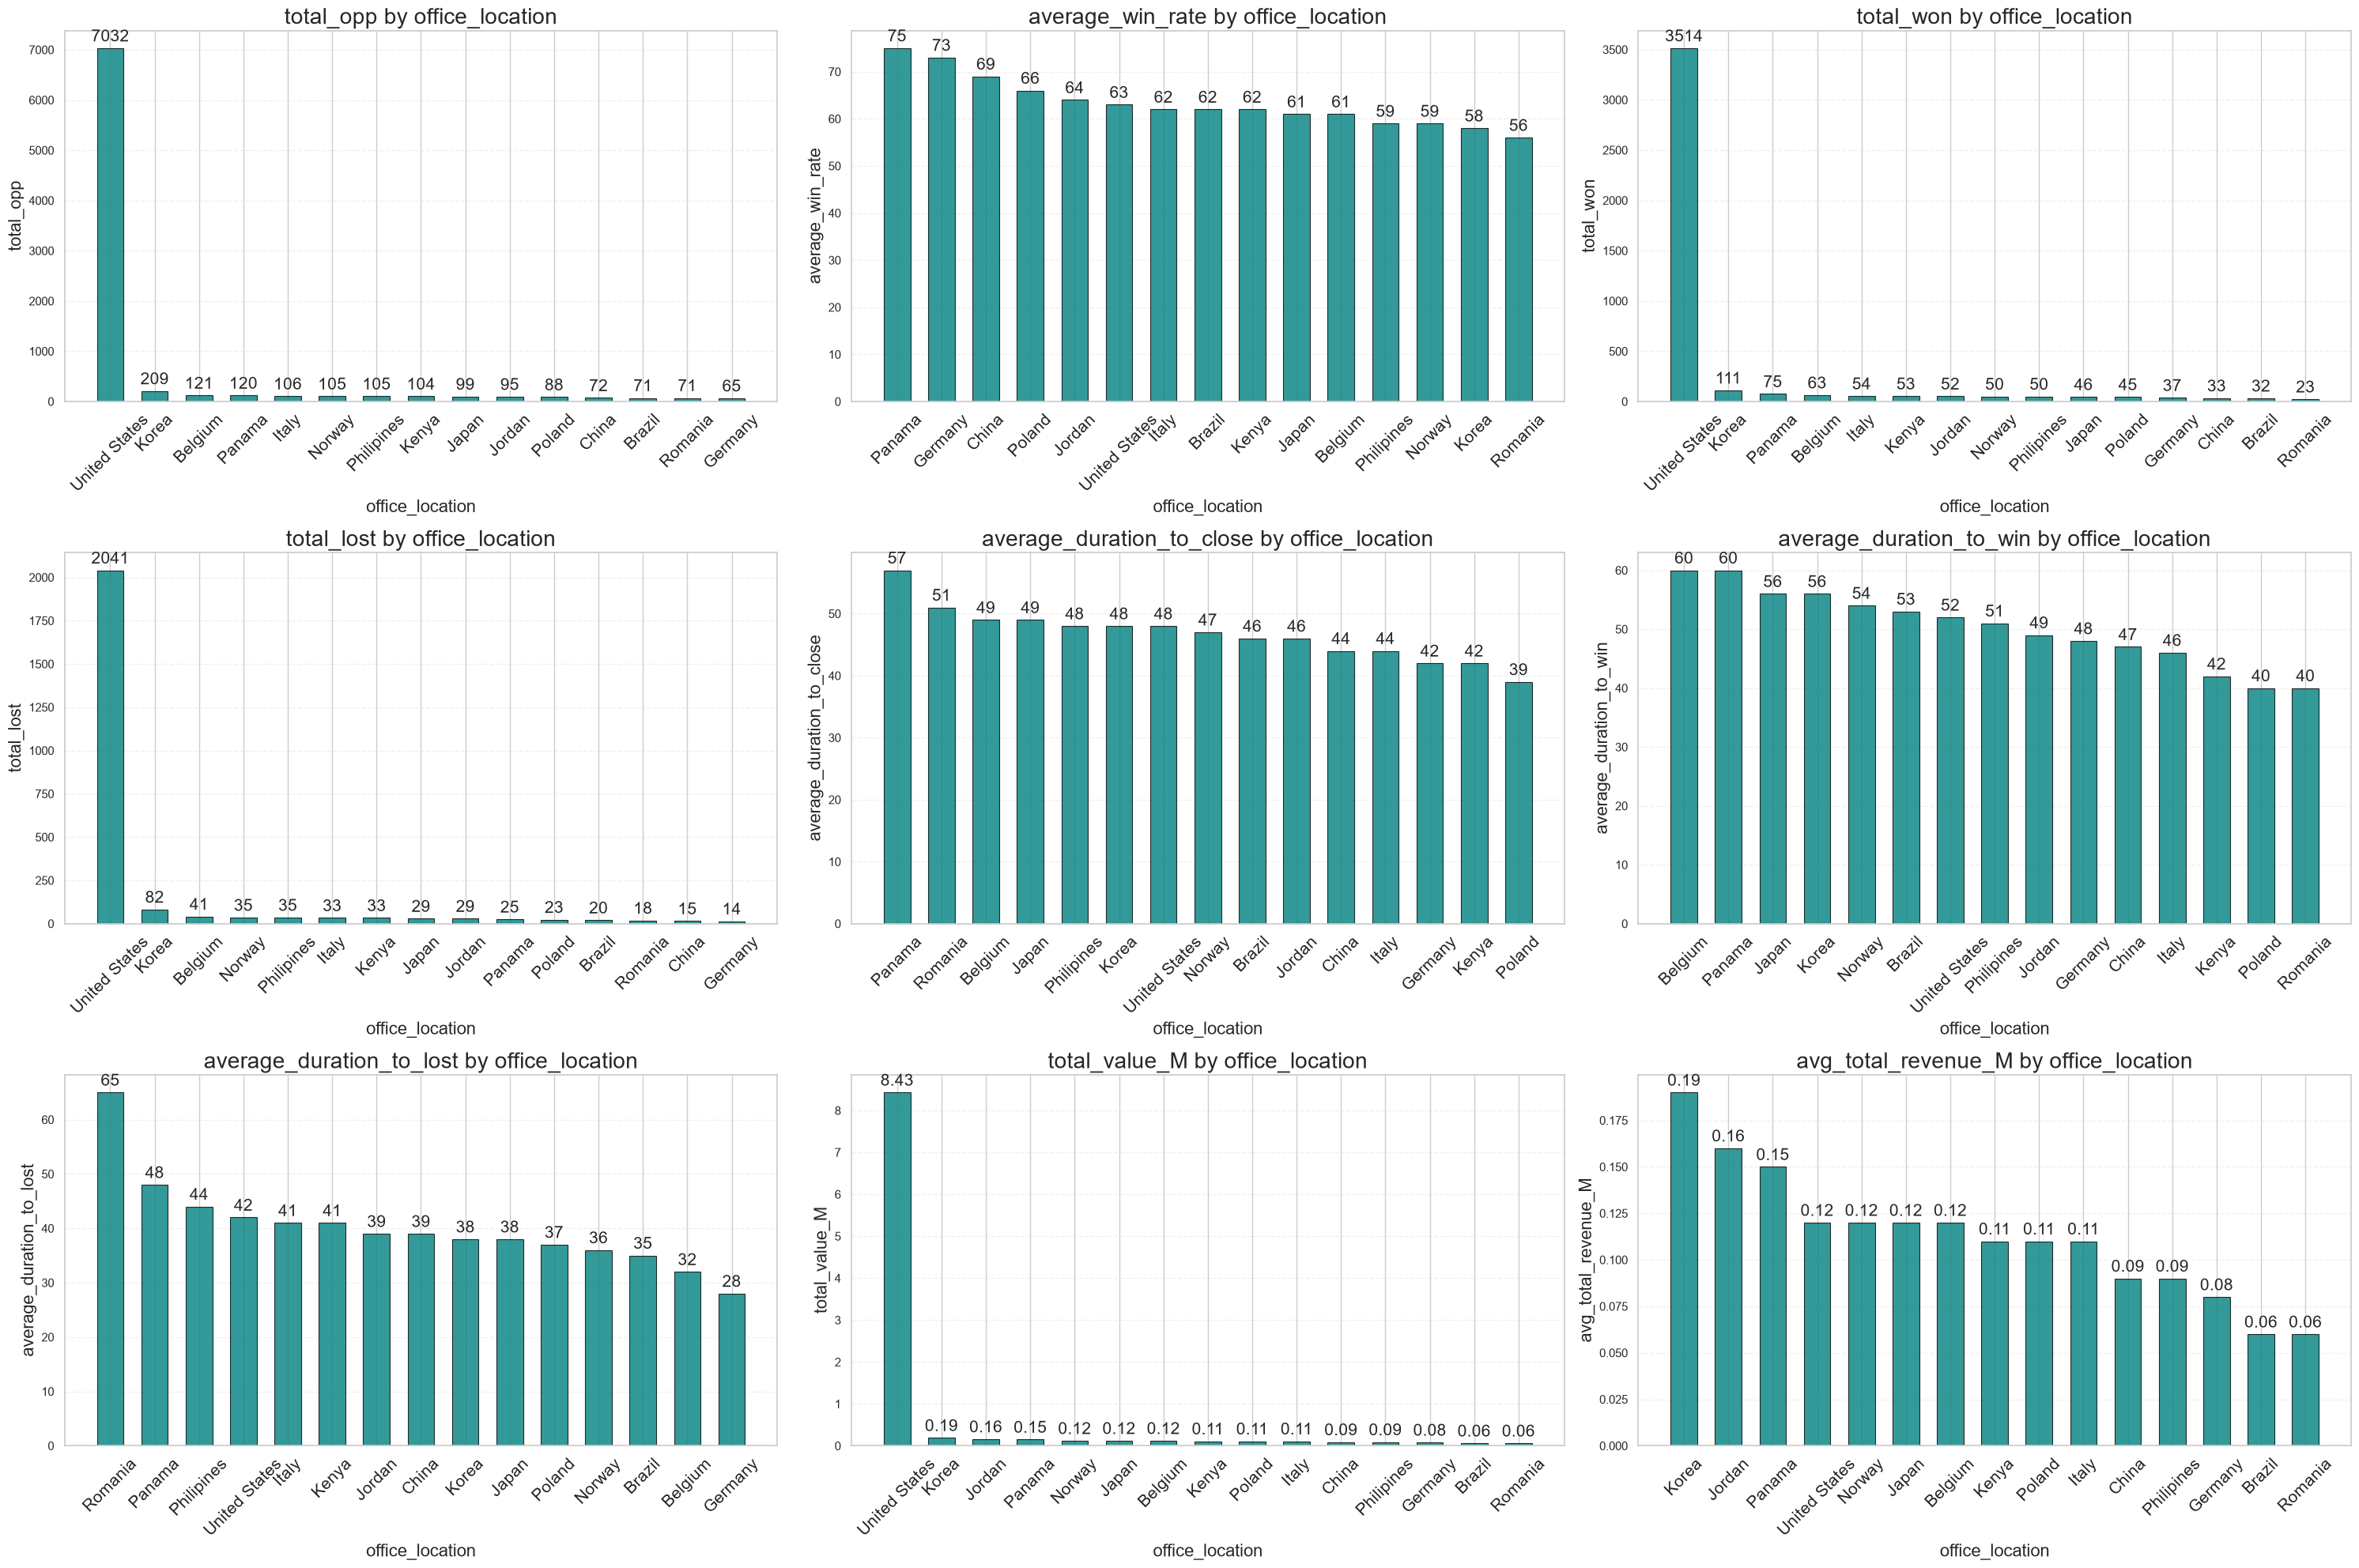

In [29]:
breakdown_bar(df_account_char,'office_location')

The US dominates sales activity and contributes the largest total commercial value, which is consistent with its account concentration of 84% of the entire dataset. Panama has the highest average win rate, while Korea records the highest average account value. In terms of the sales cycle, Poland demonstrates the fastest opportunity closure time, whereas Romania has the longest duration for Lost opportunities.

These findings indicate that each country has distinct performance characteristics. The US is significant in terms of commercial contribution, Panama stands out in conversion performance, Korea leads in average account value, and Poland could serve as a benchmark for evaluating sales cycle efficiency.

####
*Company Size & Scale*

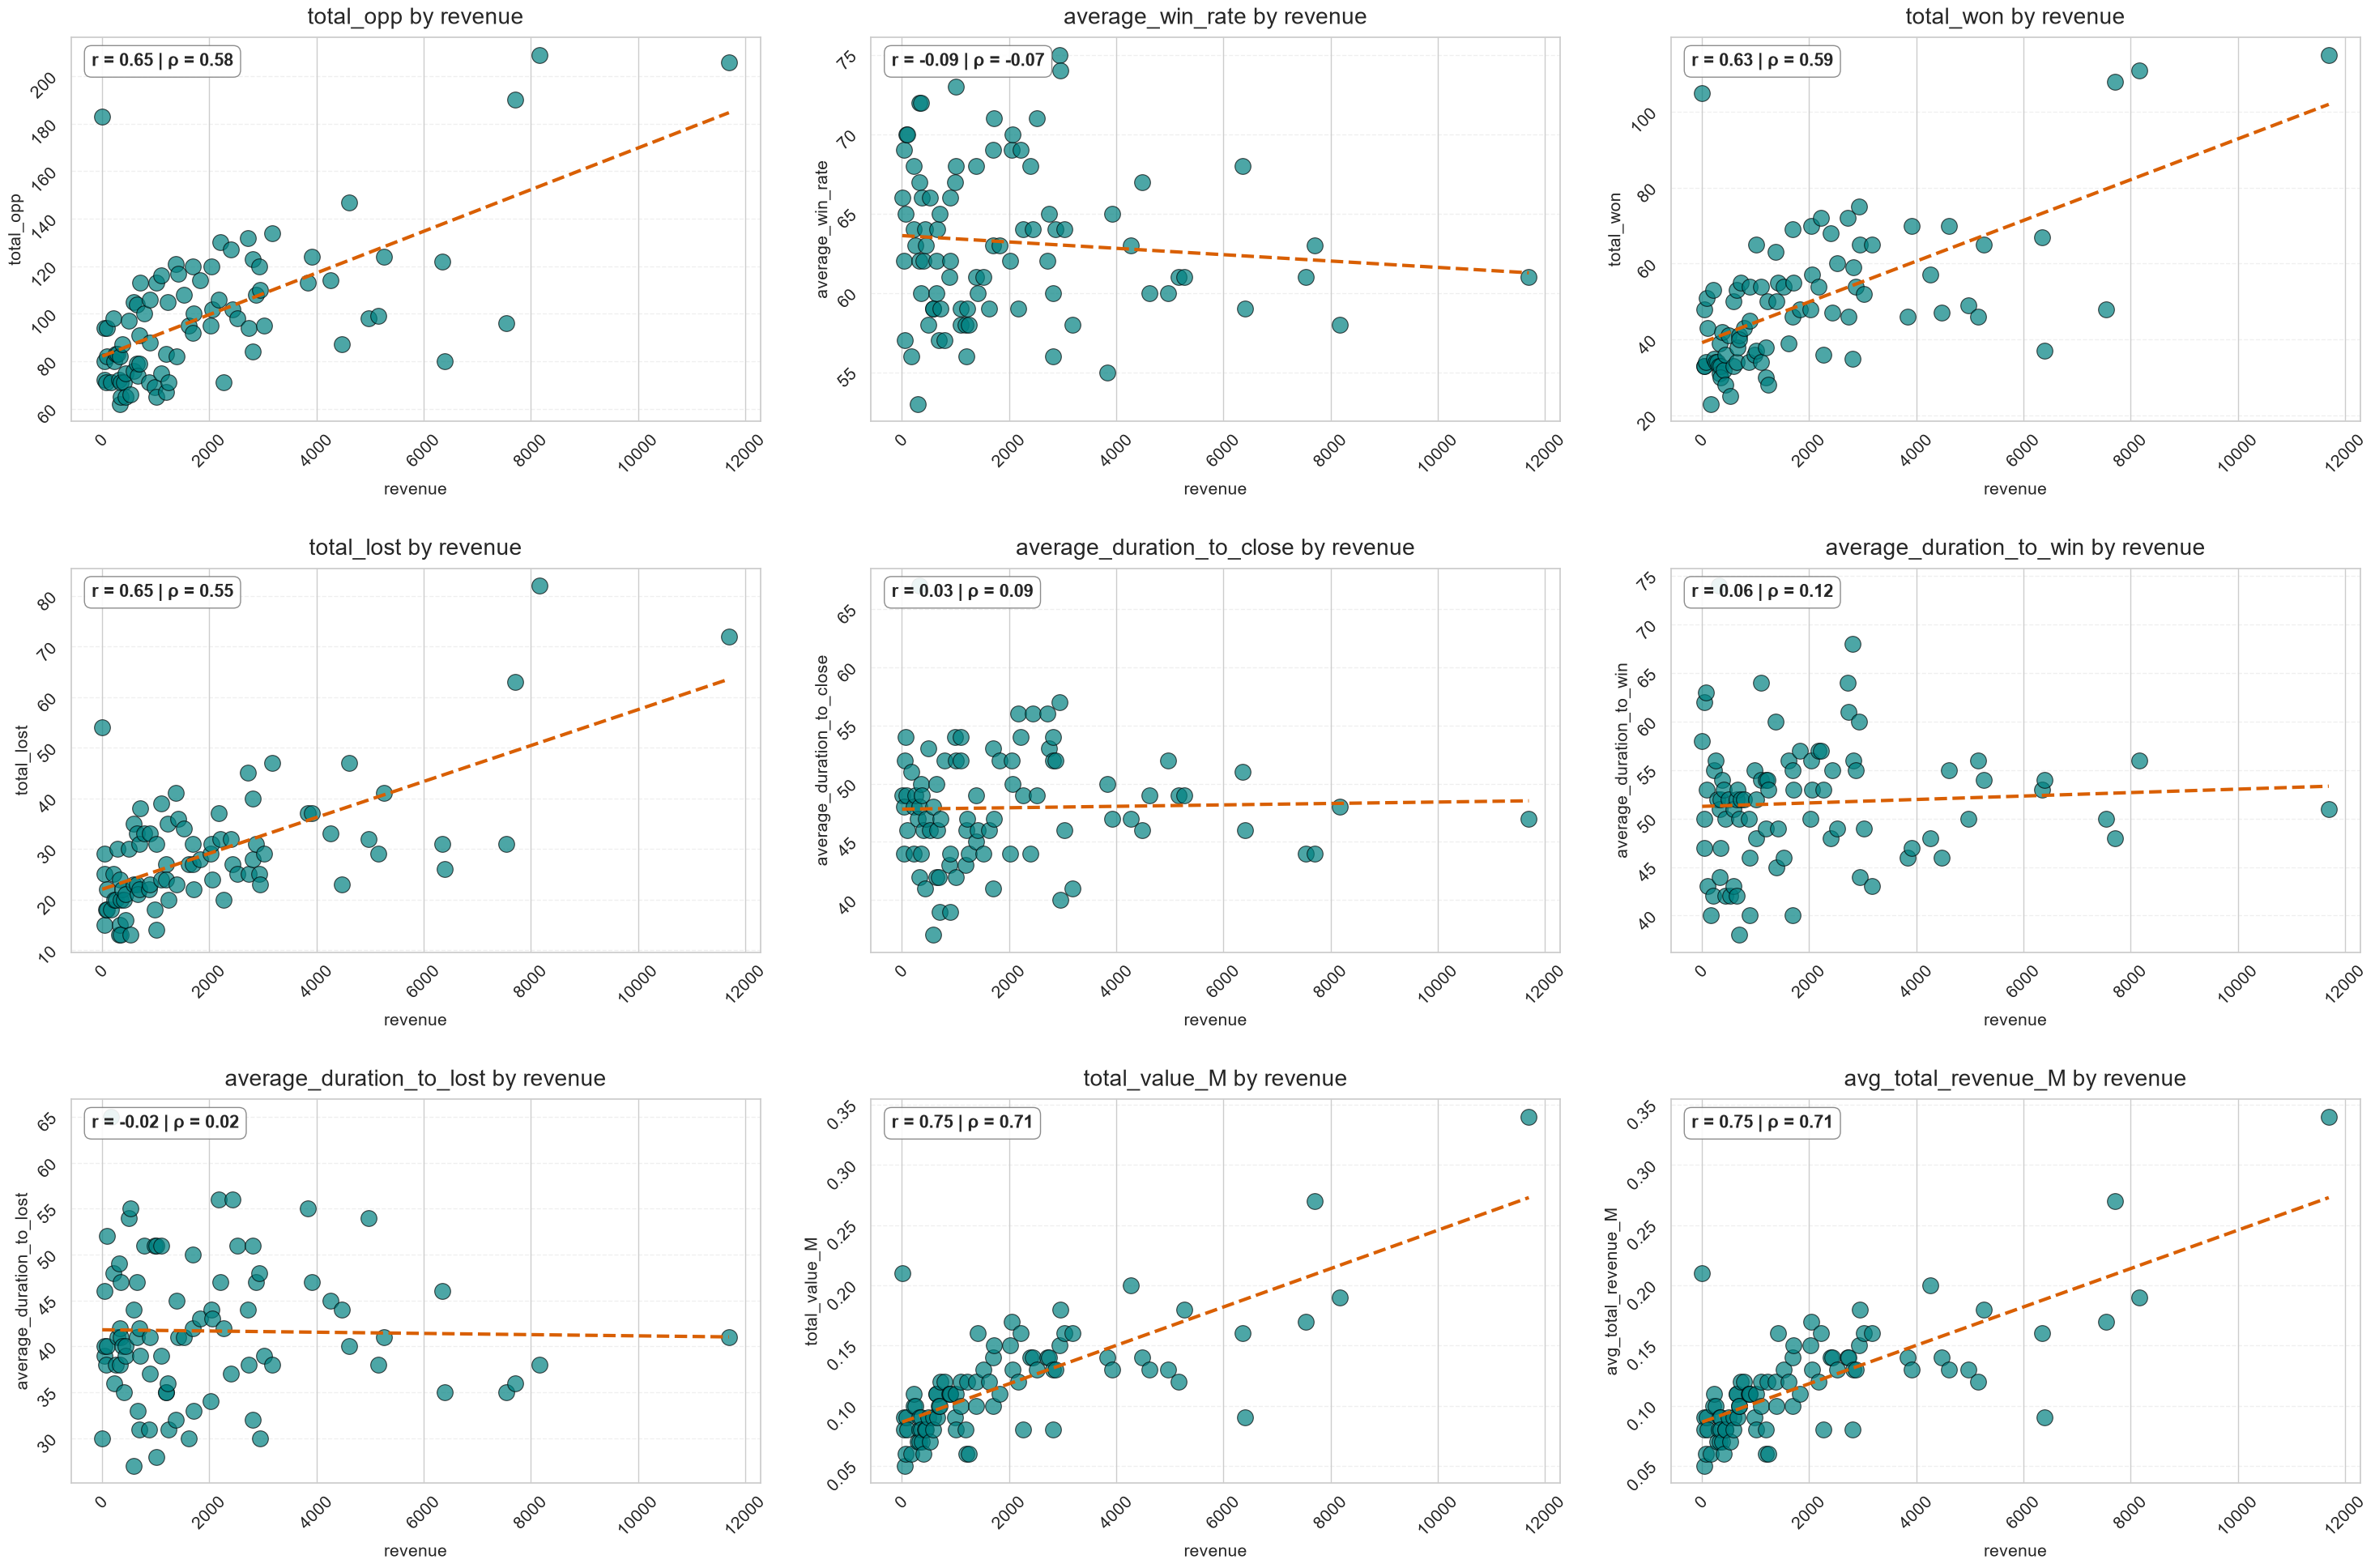

In [30]:
breakdown_plot(df_account_char,'revenue')

The analysis indicates that clients with higher business revenue tend to have greater commercial value and larger sales pipeline volumes. A relatively strong positive correlation is observed between client revenue and Account Value (r = 0.75), while moderate positive correlations are found with Total Opportunities (r = 0.65) and Total Won (r = 0.63).

However, client revenue does not show a meaningful relationship with conversion performance or sales cycle duration. This suggests that financially larger clients do not necessarily have higher opportunity conversion rates or faster sales processes.

Overall, client revenue could serve as an initial indicator for identifying accounts with potentially higher commercial value. However, it should be combined with other account characteristics and validated further before being used as a basis for account prioritization.


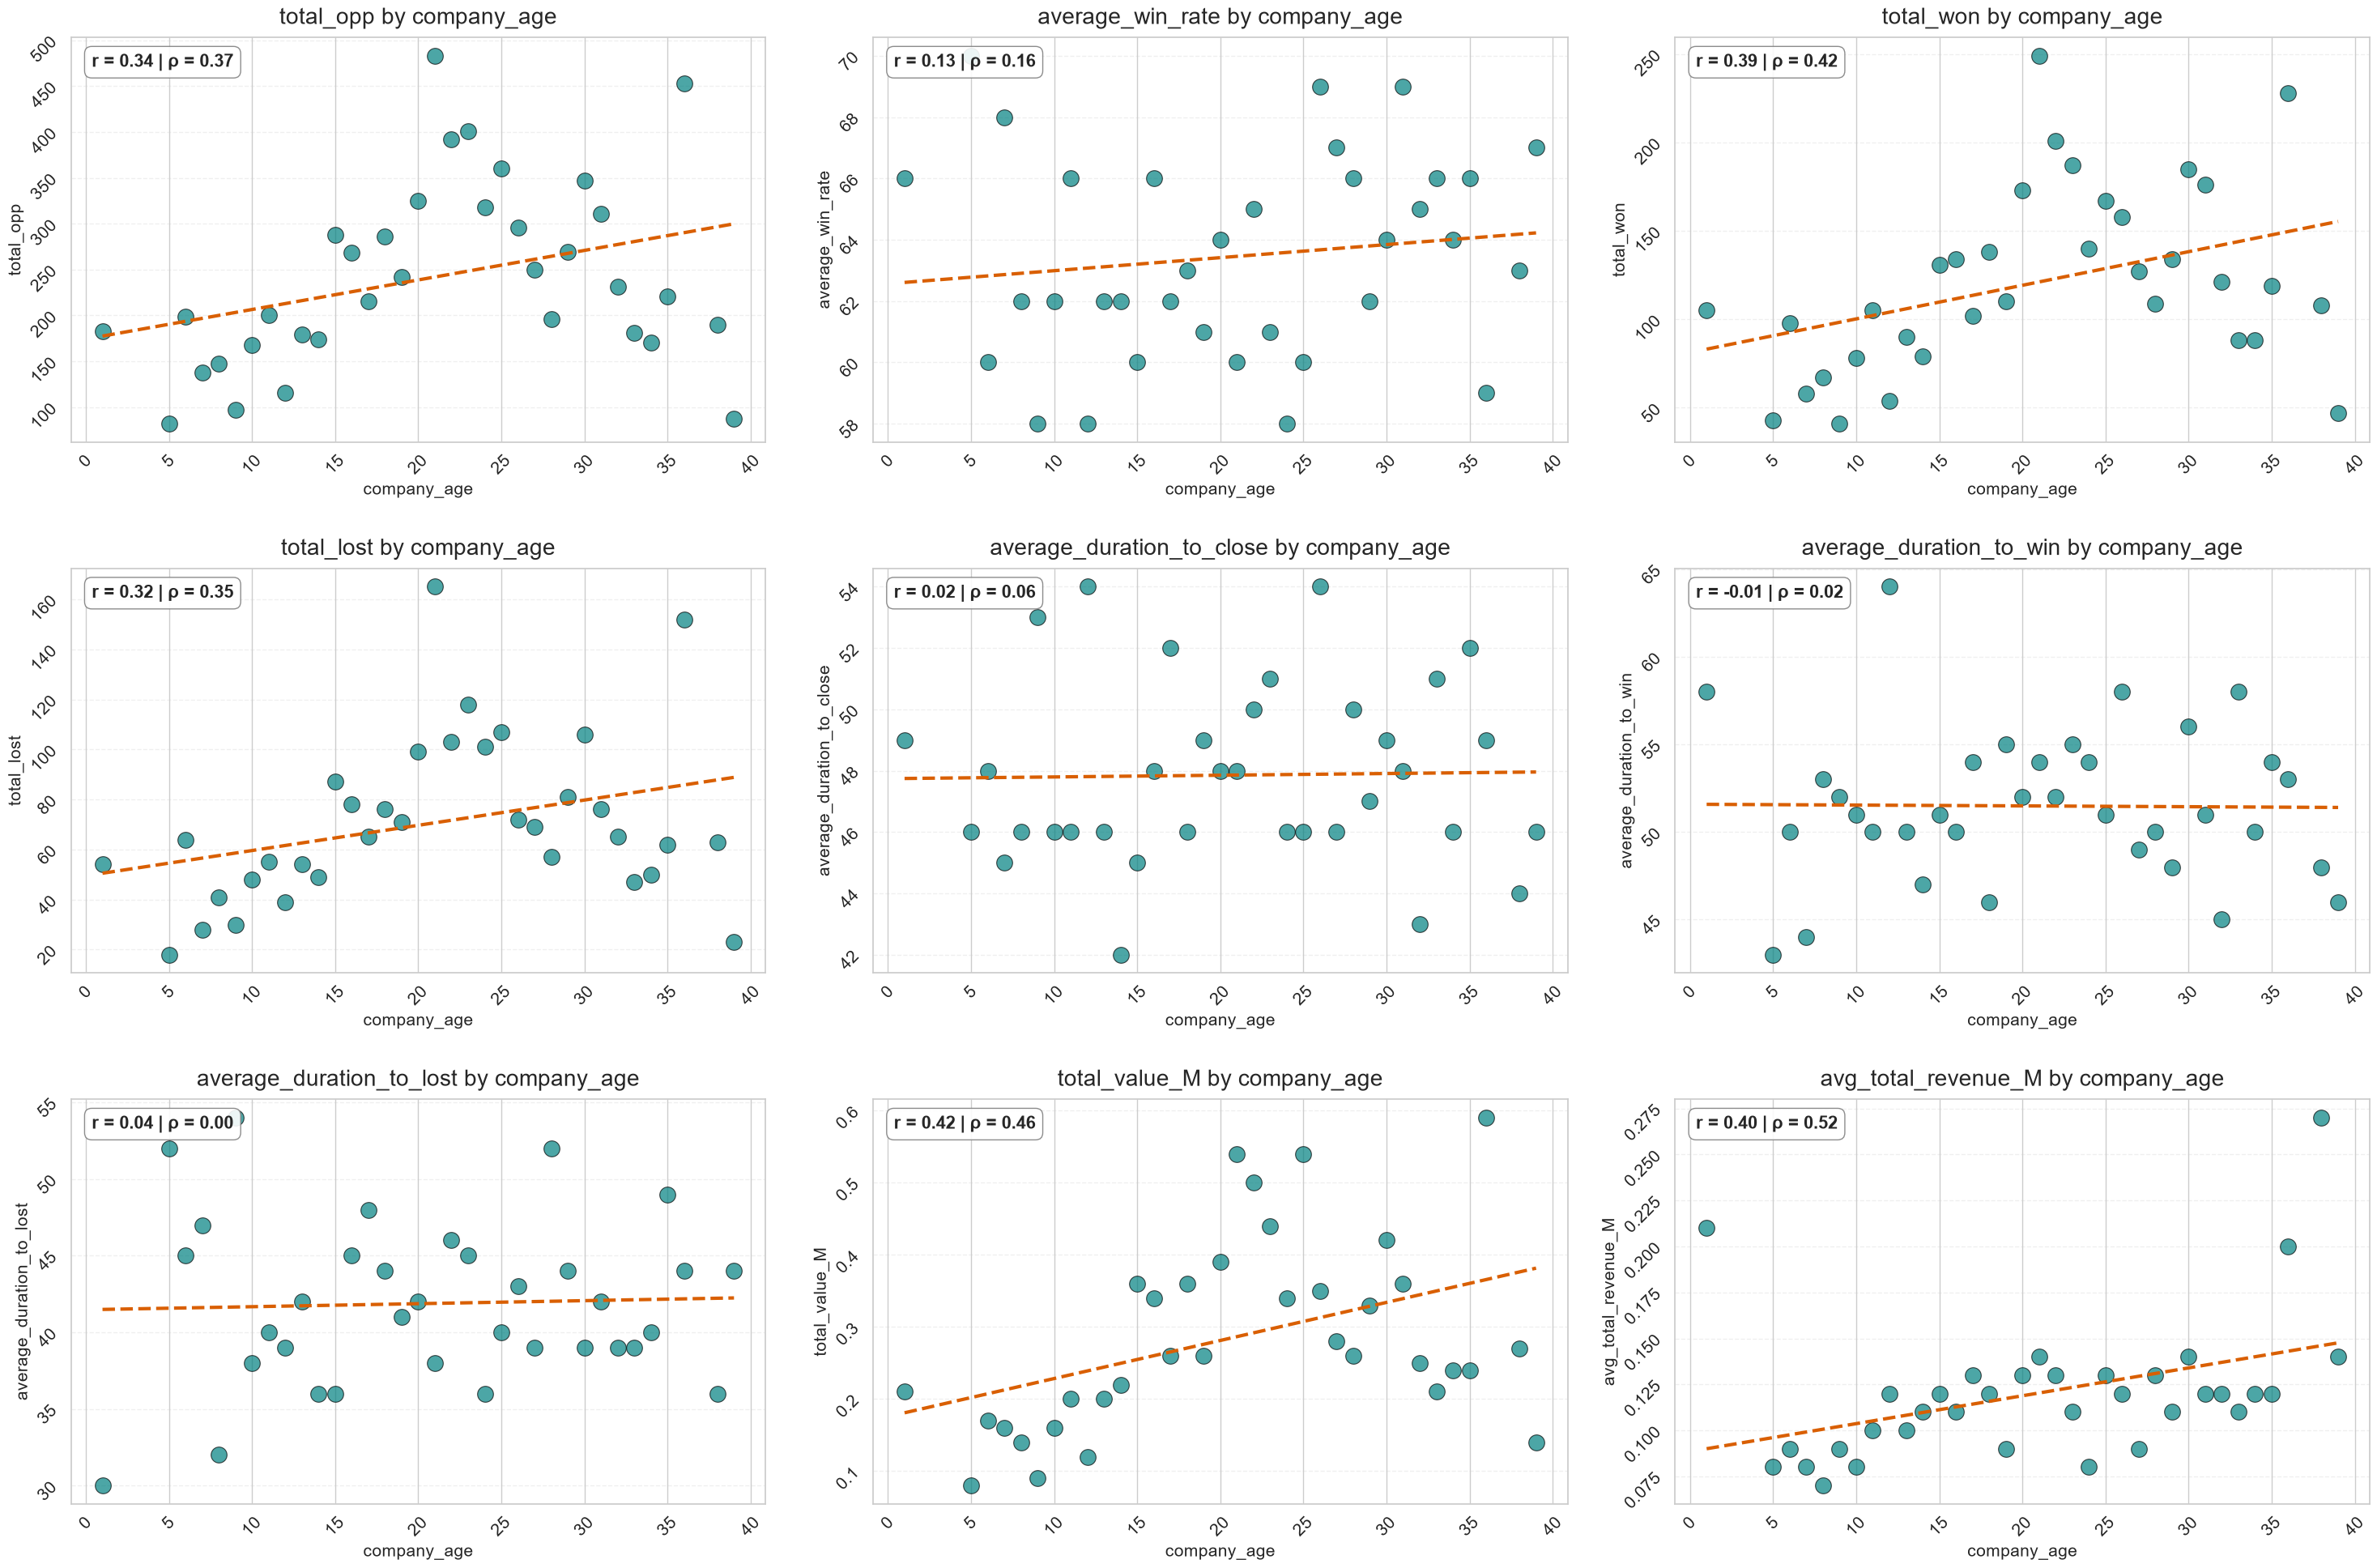

In [31]:
breakdown_plot(df_account_char,'company_age')

The analysis indicates that older client companies tend to have greater Account Value, and larger sales pipeline volumes. The strongest positive correlation is observed between Company Age and Average Client Revenue (r = 0.49), followed by Total Account Value (r = 0.42) and Total Won (r = 0.39).

However, Company Age shows almost no meaningful relationship with sales cycle duration and only a weak relationship with conversion performance. This suggests that more established companies tend to have greater business scale and commercial activity, but they do not necessarily demonstrate better opportunity conversion rates or faster sales processes.

Company Age may serve as a supporting indicator for understanding client business scale and identifying accounts with potentially higher commercial value. However, it should not be used as a standalone indicator for predicting sales efficiency or prioritizing accounts.


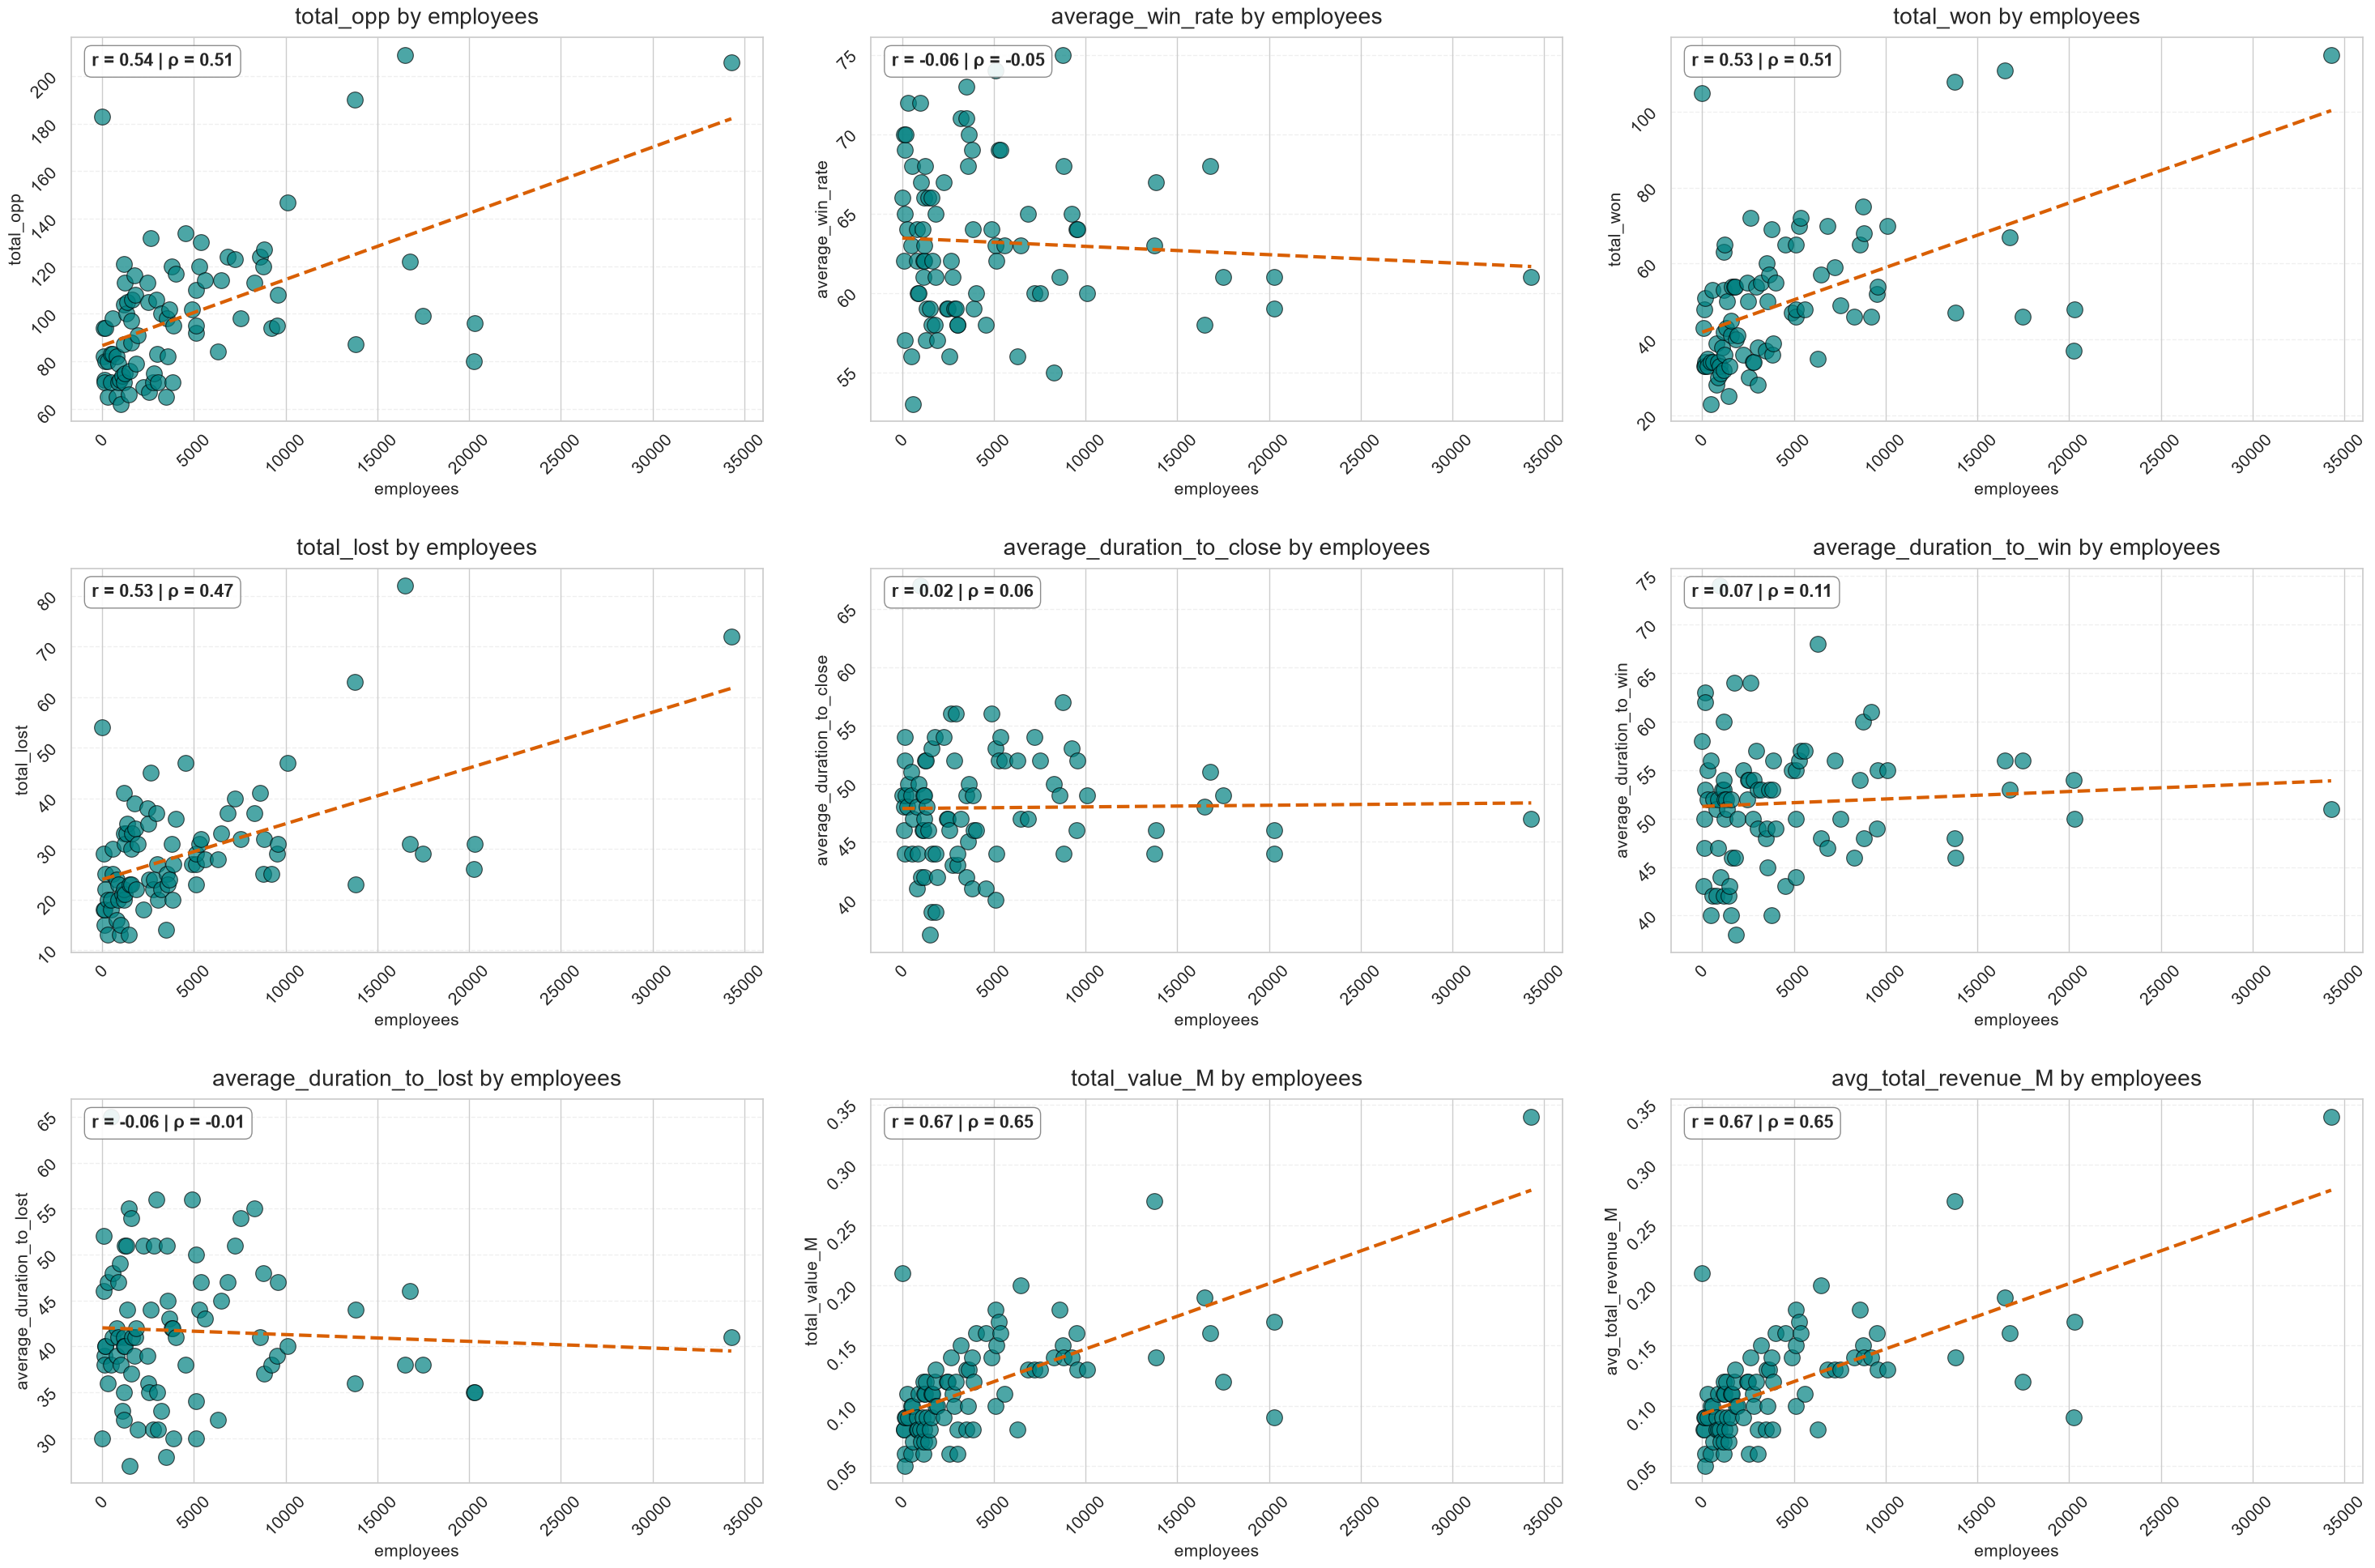

In [32]:
breakdown_plot(df_account_char,'employees')

The analysis indicates that companies with larger workforces tend to have greater business revenue, higher Account Value, and larger sales pipeline volumes. The strongest positive correlations are observed between the number of employees and both Total Account Value (r = 0.67) and Average Client Revenue (r = 0.67). Moderate positive correlations are also found with Total Opportunities (r = 0.54) and Total Won (r = 0.53).

However, Company Size shows almost no meaningful relationship with conversion performance or sales cycle duration. This suggests that larger companies tend to have greater business scale and sales activity, but they do not necessarily demonstrate higher opportunity conversion rates or faster sales processes.

Overall, the number of employees may serve as a supporting indicator for understanding client business scale and identifying accounts with potentially higher commercial value. However, it should not be used as a standalone indicator for predicting sales efficiency or prioritizing accounts.

In [33]:

value_threshold = df_accounts_summary['account_value'].median()
win_threshold = df_accounts_summary['win_rate'].median()
duration_threshold = df_accounts_summary['avg_duration_to_win'].median()

high_value = df_accounts_summary['account_value'] >= value_threshold
high_win = df_accounts_summary['win_rate'] >= win_threshold
fast_closing = df_accounts_summary['avg_duration_to_win'] <= duration_threshold

conditions = [
    high_value & high_win & fast_closing,
    high_value & ~high_win & fast_closing,
    high_value & ~high_win & ~fast_closing,
    high_value & high_win & ~fast_closing,
    ~high_value & high_win & fast_closing,
    ~high_value & high_win & ~fast_closing,
    ~high_value & ~high_win & fast_closing,
    ~high_value & ~high_win & ~fast_closing
]

categories = [
    'Top Performers',
    'High Value - Low Conversion',
    'High Value - Slow & Low Conversion',
    'High Value - Slow Closing',
    'Efficient Accounts',
    'Low Value - Slow Closing',
    'Low Value - Fast & Low Conversion',
    'Low Performers'
]

df_accounts_summary['performance_segment'] = np.select(
    conditions,
    categories,
    default='Needs Data Review'
)


| Account Value | Win Rate | Duration to Win | Category |
|:---:|:---:|:---:|---|
| High | High | Fast | Top Performers |
| High | Low | Fast / Slow | High Value – Low Conversion |
| Low | High | Fast | Efficient Accounts |
| Low | Low | Slow | Low Performers |
| High | High | Slow | High Value – Slow Closing |
| Low | High | Slow | Low Value – Slow Closing |
| Low | Low | Fast | Low Value – Fast & Low Conversion |

In [34]:
segment_summary = (
    df_accounts_summary
    .groupby('performance_segment')
    .agg(
        total_accounts=('account', 'nunique'),
        total_account_value=('account_value', 'sum'),
        avg_account_value=('account_value', 'mean'),
        avg_win_rate=('win_rate', 'mean'),
        avg_duration_to_win=('avg_duration_to_win', 'mean')
    )
    .reset_index()
)


total_accounts = segment_summary['total_accounts'].sum()

segment_summary['account_percentage'] = (
    segment_summary['total_accounts'] / total_accounts * 100
)


segment_summary = segment_summary.sort_values(
    'total_account_value',
    ascending=False
)

display(segment_summary.round(0))


,performance_segment,total_accounts,total_account_value,avg_account_value,avg_win_rate,avg_duration_to_win,account_percentage
1,High Value - Low Conversion,12,1833510.0,152792.0,60.0,49.0,14.0
3,High Value - Slow Closing,11,1659888.0,150899.0,68.0,56.0,13.0
7,Top Performers,9,1496246.0,166250.0,67.0,47.0,11.0
2,High Value - Slow & Low Conversion,11,1478737.0,134431.0,60.0,57.0,13.0
0,Efficient Accounts,13,1145840.0,88142.0,68.0,45.0,15.0
5,Low Value - Fast & Low Conversion,12,1036293.0,86358.0,59.0,48.0,14.0
6,Low Value - Slow Closing,10,851393.0,85139.0,66.0,57.0,12.0
4,Low Performers,7,503627.0,71947.0,58.0,57.0,8.0
